### Stock Analysis with AI

In [14]:
#Imports
import os
import re
import pandas as pd
import numpy as np
import requests
from dotenv import load_dotenv
from bs4 import BeautifulSoup
from IPython.display import Markdown, display
from openai import OpenAI
from IPython.display import Markdown, display, update_display
import ollama
import yfinance as yf
import mplfinance as mpf
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import gradio as gr
from datasets import load_dataset
from datetime import datetime, timedelta
from pathlib import Path
import requests
from datetime import datetime
from collections import defaultdict
import logging
import requests, re, random, json
from collections import Counter
import matplotlib.pyplot as plt
import json, textwrap
from langchain.document_loaders import DirectoryLoader, TextLoader
from langchain.text_splitter import CharacterTextSplitter
from langchain.schema import Document
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_chroma import Chroma
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import plotly.graph_objects as go
from langchain.memory import ConversationBufferMemory
from langchain.chains import ConversationalRetrievalChain
from langchain.embeddings import HuggingFaceEmbeddings
from langchain.text_splitter import RecursiveCharacterTextSplitter
from transformers import AutoTokenizer, AutoModelForCausalLM, pipeline
from io import StringIO
from nsetools import Nse

In [2]:
# Load 1 year of data
stock_name = "Tanla"
period = "1y"
data = yf.Ticker(f"{stock_name}.NS").history(period="max")

fig = make_subplots(rows=2, cols=1, shared_xaxes=True, row_heights=[0.7, 0.3])

# Price (candlestick) and volume bars
fig.add_trace(go.Candlestick(x=data.index, open=data.Open, high=data.High,
                             low=data.Low, close=data.Close,
                             increasing_line_color='green',
                             decreasing_line_color='red'), row=1, col=1)

fig.add_trace(go.Bar(x=data.index, y=data.Volume, marker_color=['green' if row.Close >= row.Open else 'red' for _, row in data.iterrows()]), row=2, col=1)

fig.update_layout(height=700, showlegend=False, xaxis_rangeslider_visible=False, template='plotly_dark')
fig.show()

In [3]:
# Technical analysis
def get_data(ticker, period="1y"):
    data = yf.Ticker(f"{ticker}.NS").history(period=period)
    data.reset_index(inplace=True)
    return data

def tech_Chart(data):
    fig = make_subplots(rows=2, cols=1, shared_xaxes=True, row_heights=[0.7, 0.3])
    fig.add_trace(go.Candlestick(x=data.index, open=data.Open, high=data.High,
                             low=data.Low, close=data.Close,
                             increasing_line_color='green',
                             decreasing_line_color='red'), row=1, col=1)
    fig.add_trace(go.Bar(x=data.index, y=data.Volume, marker_color=['green' if row.Close >= row.Open else 'red' for _, row in data.iterrows()]), row=2, col=1)
    fig.update_layout(height=700, showlegend=False, xaxis_rangeslider_visible=False, template='plotly_dark')
    return fig
    
def technical_Summary(data):
    summary = {"ticker"         : data['Ticker'][0] if 'Ticker' in data else "Stock not given",
               "latest_close"   : round(data["Close"].iloc[-1], 2),
               "latest_open"    : round(data["Open"].iloc[-1], 2),
               "highest_high"   : round(data["High"].max(), 2),
               "lowest_low"     : round(data["Low"].min(), 2),
               "average_volume" : int(data["Volume"].mean()),
               "recent_rsi"     : round(calc_RSI(data["Close"]), 2),
               "data_points"    : data[["Date", "Open", "High", "Low", "Close", "Volume"]].tail(30).to_dict(orient="records")}
    return summary

def calc_RSI(series, period=14):
    delta = series.diff()
    gain = delta.clip(lower=0).rolling(window=period).mean()
    loss = -delta.clip(upper=0).rolling(window=period).mean()
    rs = gain / loss
    return 100 - (100 / (1 + rs)).iloc[-1]

# gpt 4.0-mini model
load_dotenv(override=True)
api_key = os.getenv('OPENAI_API_KEY')

if not api_key:
    print("No API key found")
elif not api_key.startswith("sk-proj-"):
    print("API key, not starting with given input, check file again")
elif api_key.strip() != api_key:
    print("API key contains blank spaces")
else:
    print("API key found!")


# GPT model 
openai = OpenAI()
def stock_techAnalysis(summary_dict):
    # Send to GPT-4o Mini or similar
#     prompt = f"""Given the following technical stock summary: {summary_dict}

# Analyze the support and resistance levels, give Buy/Sell/Hold advice,
# and mention short- and long-term targets. Return the output as a clean table.
# Don't give any other details, just give support and resistance levels, give Buy/Sell/Hold advice, short-long-trem targets in tabular form & conclusion in 1 sentence. 
#     """

    system_promptMsg = "You are a stock market assistant specializing in analyzing patterns, prices of given stocks, and give techincal analysis of that stock."
    user_promptMsg = f"""Given the following technical stock summary: {summary_dict}
    Analyze the support and resistance levels, give Buy/Sell/Hold/stop loss advice,
    and mention short- and long-term targets, breakout- yes if stock is breakout/no if it is not currently breakout/& if bullish, what price it will be breakout, buy/sell levels, Return the output as a clean table.
    Don't give any other details, just give support and resistance levels, give Buy/Sell/Hold advice, short-long-trem targets in tabular form & conclusion in 1 sentence. 
    Give a technical score out of 100** at the end based on how strong the technical indicators for buying that stock are (higher is better).
    Return output ONLY in this JSON format like this:
    {{"support_level": 3413.5, "resistance_level": 3485,"recommendation": "Buy", "short_term_target": 3485,"long_term_target": 3860,"breakout": "No","buy_level": 3455,"sell_level": 3413.5,"technical_score": 72}}
    """
    requestMessage = [{"role": "system", "content": system_promptMsg}, {"role": "user", "content": user_promptMsg}]
    response = openai.chat.completions.create(model="gpt-4o-mini", messages=requestMessage)
    summary_text = response.choices[0].message.content.strip()
    if summary_text.startswith("```"):
        summary_text = summary_text.split("```")[1].strip() 
        if summary_text.startswith("json"):
            summary_text = summary_text.split("json")[1].strip() 
    labels = json.loads(summary_text)
    return  labels


API key found!


In [4]:
data = get_data('TCS')
a = technical_Summary(data)
summary                = technical_Summary(data)
table_text             = stock_techAnalysis(summary)
print(table_text)

{'support_level': 3397.6, 'resistance_level': 3435.3, 'recommendation': 'Hold', 'short_term_target': 3485, 'long_term_target': 3860, 'breakout': 'No', 'buy_level': 3420, 'sell_level': 3390, 'technical_score': 65}


In [4]:
# Fundamental analysis
load_dotenv() 
api_key = os.getenv("FINNHUB_API_KEY")
if not api_key:
    print("API key not found")
else:
    print("API key found")
    
# def fundamental_Analysis(ticker):
#     url = f"https://finnhub.io/api/v1/stock/metric?symbol={ticker}.NS&metric=all&token={FINNHUB_API_KEY}"
#     response = requests.get(url)
#     metrics = response.json().get("metric", {})

#     fundamentals = {"ticker": ticker,
#                   "PE_ratio": metrics.get("peInclExtraTTM"),
#                        "ROE": metrics.get("roeTTM"),
#                       "ROCE": metrics.get("roicTTM"),
#                 "market_cap": metrics.get("marketCapitalization"),
#                     "ebitda": metrics.get("ebitdaTTM"),
#                    "revenue": metrics.get("revenueTTM"),
#                 "book_value": metrics.get("bookValuePerShareAnnual"),
#             "debt_to_equity": metrics.get("totalDebt/totalEquityAnnual"),
#              "current_ratio": metrics.get("currentRatioAnnual")}
#     return fundamentals

def fundamental_Analysis(ticker):
    t = yf.Ticker(f"{ticker}.NS")
    info = t.info
    fund = {
        "pe": info.get("trailingPE"),
        "forward_pe": info.get("forwardPE"),
        "pb": info.get("priceToBook"),
        "roe": info.get("returnOnEquity"),
        "roce": info.get("returnOnCapital"),
        "market_cap": info.get("marketCap"),
        "beta": info.get("beta"),
        "dividend_yield": info.get("dividendYield")
    }
    # financial statements
    qs = t.quarterly_financials.transpose()[["Net Income", "Total Revenue"]].reset_index().tail(6)
    as_ = t.financials.transpose()[["Net Income", "Total Revenue"]].reset_index().tail(5)
    fund["last_6_quarters"] = qs.to_dict(orient="records")
    fund["last_5_years"] = as_.to_dict(orient="records")
    return fund
    
def stock_fundAnalysis(fundamental_dict):
    system_msg = "You are a fundamental stock analyst. Use key financial metrics to analyze stock fundamentals and give recomendation based on fuon stock fundamentals."
    user_msg = f"""This is the fundamental data of that particular stock: {fundamental_dict},
    Based on this, evaluate the company's financial health, growth, profitability,fundamentals, net profit & net sales over last years and quarterly results, 
    and return a recommendation only as (Strong Buy / Buy / Neutral / No Buy / Strong Sell) along with as under/over/neutral valued company with very strong, strong, neural, bad, or very bad growth potential, 
    only give strong buy when there is a  high growth potential, and fundamentals seems to be strong along with fairly valued company share price,
    give this in tabular form,  give this in very small wording, dont give bigger description or anything bigger wording.
    Also based on all above given recommendations, like Strong Buy / Buy / Neutral / No Buy / Strong Sell recommendations give an overall score out of 100.
    Return output ONLY in this JSON format:
    {{"recommendation": "Strong Buy", "valuation": "Fair", "growth_potential": "Strong", "score": 88}}"""
    fund_Msg = [{"role": "system", "content": system_msg}, {"role": "user", "content": user_msg}]
    response = openai.chat.completions.create(model="gpt-4o-mini", messages=fund_Msg)
    response_text = response.choices[0].message.content.strip()
    keys = ['pe', 'forward_pe', 'pb', 'roe', 'roce', 'market_cap', 'beta', 'dividend_yield']
    op_dict = {k : fundamental_dict.get(k) for k in keys}
    if response_text.startswith("```"):
        response_text = response_text.split("```")[1].strip() 
        if response_text.startswith("json"):
            response_text = response_text.split("json")[1].strip() 
    labels = json.loads(response_text)
    op_dict.update(labels)
    return op_dict
   

API key found


In [166]:
a = fundamental_Analysis('SBIN')
fund = stock_fundAnalysis(a)  
display(fund)

{'pe': 9.441759,
 'forward_pe': 9.922584,
 'pb': 1.5032758,
 'roe': 0.17212999,
 'roce': None,
 'market_cap': 7320865603584,
 'beta': 0.521,
 'dividend_yield': 1.94,
 'recommendation': 'Buy',
 'valuation': 'Fair',
 'growth_potential': 'Strong',
 'score': 75}

In [5]:


nse = Nse()

def get_nse_stock_symbols():
    url = "https://archives.nseindia.com/content/indices/ind_nifty500list.csv"
    headers = {"User-Agent": "Mozilla/5.0"}
    r = requests.get(url, headers=headers)
    df = pd.read_csv(StringIO(r.text))  
    return df['Symbol'].tolist()

# Breakout detection using multiple strategies
def stocks_Breakout(symbol):
        df = yf.download(f"{symbol}.NS", period="1y", interval="1d", progress=False)
        if df.empty or len(df) < 50:
            return False, []
        
        df = df.sort_index()
        df = df[~df.index.duplicated(keep='last')]
        close = df['Close']
        # Strategy 1: 20-day High Breakout
        high_br = (close.iloc[-1] > close.iloc[-21:-1].max()).item()
        # Strategy 2: Bollinger Bands Breakout
        sma20  = close.rolling(20).mean()
        std20  = close.rolling(20).std()
        upper  = sma20 + 2 * std20
        bb_br  = (close.iloc[-1] > upper.iloc[-1]).item()
        # Strategy 3: EMA 20/50 Crossover
        ema20_vals   = close.ewm(span=20).mean().to_numpy()
        ema50_vals   = close.ewm(span=50).mean().to_numpy()
        ema_br = bool((ema20_vals[-2] < ema50_vals[-2]) and (ema20_vals[-1] > ema50_vals[-1]))
        # Strategy 4: 200 days Moving Average
        close = close.squeeze() 
        rolling200 = close.rolling(200).mean()
        sma200_last = rolling200.iloc[-1]
        ma200_br = close.iloc[-1] > sma200_last

        strategies = []
        if high_br: strategies.append("20d_high")
        if bb_br  : strategies.append("bollinger")
        if ema_br : strategies.append("ema_20_50")
        if ma200_br : strategies.append("above_200dma")
        return bool(strategies), strategies
        
# # Main logic
# symbols   = get_nse_stock_symbols()
# breakouts = []

# for symbol in symbols:
#     ok, strats = stocks_Breakout(symbol)
#     if ok:
#         breakouts.append({"symbol": symbol, "strategies": strats})
# # sort
# breakouts.sort(key=lambda x: len(x["strategies"]), reverse=True)
# print("Breakout stocks")

# for b in breakouts:
#     print(f"{b['symbol']}: {', '.join(b['strategies'])}   "
#           f"({len(b['strategies'])} breakout{'s' if len(b['strategies'])>1 else ''})")

In [6]:
def get_breakout_stocks(strategy_filter=None):
    symbols = get_nse_stock_symbols()
    breakouts = []
    for symbol in symbols:
        ok, strats = stocks_Breakout(symbol)
        if ok:
            if strategy_filter:
                # Include only if filtered strategy is present
                if strategy_filter in strats:
                    breakouts.append({"symbol": symbol, "strategies": strats})
            else:
                # Include all breakouts
                breakouts.append({"symbol": symbol, "strategies": strats})

    # Sort by number of strategies breakouts descending
    breakouts.sort(key=lambda x: len(x["strategies"]), reverse=True)
    return breakouts
    
# ema_breakouts = get_breakout_stocks(strategy_filter="ema_20_50")
# for b in ema_breakouts:
#     print(f"{b['symbol']}: {', '.join(b['strategies'])} "
#       f"({len(b['strategies'])} breakout{'s' if len(b['strategies'])>1 else ''})")

def strong_breakouts_df() -> pd.DataFrame:
    # get stocks with more that 1 breakouts from given strategies
    strong = [d for d in get_breakout_stocks() if len(d["strategies"]) >= 2]
    if not strong:
        return pd.DataFrame([{"Notice": "No strong breakouts today"}])
    return (pd.DataFrame(
        [{"Symbol": d["symbol"],
          "Strategies": ", ".join(d["strategies"]),
          "Count": len(d["strategies"])} for d in strong])
        .sort_values(["Count", "Symbol"], ascending=[False, True])
        .reset_index(drop=True))

In [ ]:
# Main logic
symbols   = get_nse_stock_symbols()
breakouts = []

for symbol in symbols:
    ok, strats = stocks_Breakout(symbol)
    if ok:
        breakouts.append({"symbol": symbol, "strategies": strats})
# sort
breakouts.sort(key=lambda x: len(x["strategies"]), reverse=True)
print("Breakout stocks")

for b in breakouts:
    print(f"{b['symbol']}: {', '.join(b['strategies'])}   "
          f"({len(b['strategies'])} breakout{'s' if len(b['strategies'])>1 else ''})")

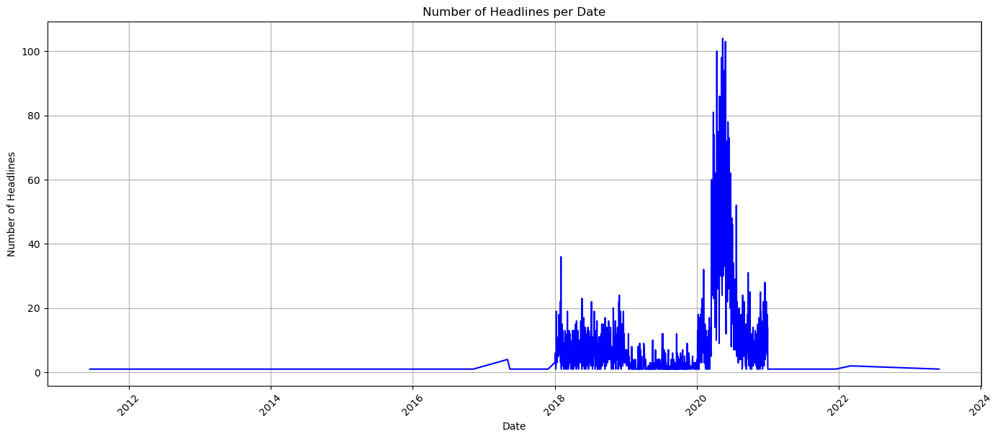

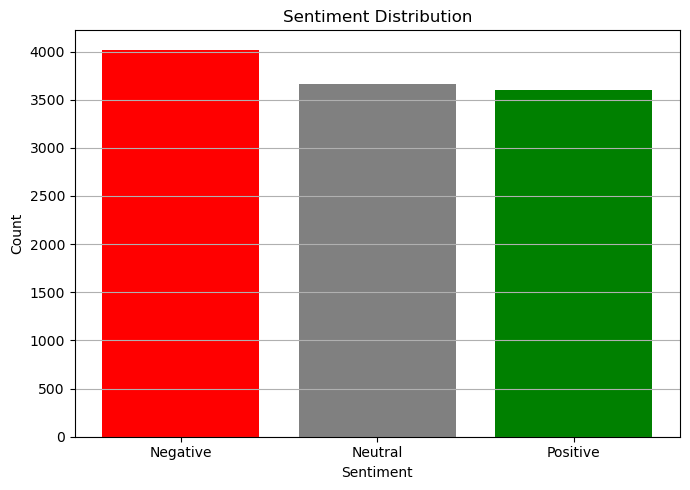

In [10]:
SAVE_FOLDER = Path("C:/Users/lenovo/projects/llm_engineering/Projects/News_stock_info")
SAVE_FOLDER.mkdir(parents=True, exist_ok=True)
SAVE_PATH = SAVE_FOLDER / "merged_news_filtered.jsonl"

data_by_date = {}
sentiment_counter = Counter()

with open(SAVE_PATH, "r", encoding="utf-8") as f:
    for line in f:
        entry = json.loads(line.strip())
        date_str = entry["date"]
        try:
            dt = datetime.strptime(date_str, "%Y_%m_%d")
            data_by_date[date_str] = len(entry.get("headlines", []))
            sentiment_counter.update(entry.get("sentiments", []))
        except:
            continue

# Sort data by date
sorted_data = sorted([(datetime.strptime(k, "%Y_%m_%d"), v) for k, v in data_by_date.items()],key=lambda x: x[0])
dates = [d[0] for d in sorted_data]
headline_counts = [d[1] for d in sorted_data]


# Plot 1: Date vs Number of Headlines
plt.figure(figsize=(14, 6))
plt.plot(dates, headline_counts, linestyle="-", color="blue")
plt.title("Number of Headlines per Date")
plt.xlabel("Date")
plt.ylabel("Number of Headlines")
plt.grid(True)
plt.tight_layout()
plt.xticks(rotation=45)
plt.show()

# Plot 2: Sentiment Distribution
plt.figure(figsize=(7, 5))
plt.bar(sentiment_counter.keys(), sentiment_counter.values(), color=["red", "gray", "green"])
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Count")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

In [22]:
SAVE_FOLDER = Path("C:/Users/lenovo/projects/llm_engineering/Projects/News_stock_info")
SAVE_PATH = SAVE_FOLDER / "merged_news_filtered.jsonl"
db_name = str(SAVE_FOLDER / "news_vectorstore")

# check NA
def all_na(sector_changes):
    return all(v == "NA" for v in sector_changes.values())

# Load and process the data
combined_documents = []

with open(SAVE_PATH, "r", encoding="utf-8") as f:
    for line in f:
        entry = json.loads(line.strip())
        date = entry["date"]
        sector_changes = entry.get("sector_changes", {})
        headlines = entry.get("headlines", [])
        sentiments = entry.get("sentiments", [])

        if all_na(sector_changes):
            continue

        for i, (headline, sentiment) in enumerate(zip(headlines, sentiments), 1):
            # Add sectoral changes at the end, common to all headlines
            combined_text = (
                f"Headline: {headline}\nSentiment: {sentiment}\n\n"
                f"Sectoral Changes:\n" +
                "\n".join(f"{s}: {v}" for s, v in sector_changes.items())
            )

            combined_documents.append(
                Document(
                    page_content=combined_text,
                    metadata={"date": date, "sentiment": sentiment}
                )
            )

print(f"Total headline-level documents: {len(combined_documents)}")

# Now split each document safely
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=800, chunk_overlap=100,
    separators=["\n\n", "\n", ".", " ", ""]
)

chunks = text_splitter.split_documents(combined_documents)
print(f"Total chunks: {len(chunks)}")

chunks = [doc for doc in chunks if len(doc.page_content) <= 3000]

embeddings = OpenAIEmbeddings()
if os.path.exists(db_name):
    print("Removing old vectorstore...")
    Chroma(persist_directory=db_name, embedding_function=embeddings).delete_collection()

# Create avectorstore
vectorstore = Chroma.from_documents(documents=chunks,embedding=embeddings,persist_directory=db_name,)

collection = vectorstore._collection
count = collection.count()
sample_embedding = collection.get(limit=1, include=["embeddings"])["embeddings"][0]
dimensions = len(sample_embedding)

print(f"\n Vectorstore ready: {count:,} vectors with {dimensions:,} dimensions")
print(f" Saved to: {db_name}")


Total headline-level documents: 8141
Total chunks: 8928
Removing old vectorstore...

 Vectorstore ready: 8,928 vectors with 1,536 dimensions
 Saved to: C:\Users\lenovo\projects\llm_engineering\Projects\News_stock_info\news_vectorstore


In [23]:
result = collection.get(include=['embeddings', 'documents', 'metadatas'])
vectors = np.array(result['embeddings'])
documents = result['documents']
metadatas = result['metadatas']

# Extract sentiment for color coding
sentiments = [meta.get('sentiment', 'neutral') for meta in metadatas]
colors = ['green' if s.lower() == 'positive' else 'red' if s.lower() == 'negative' else 'gray' for s in sentiments]

# Reduce vectors to 2D
perplexity = min(30, max(5, len(vectors) // 3))
tsne = TSNE(n_components=2, perplexity=perplexity, random_state=42)
reduced_vectors = tsne.fit_transform(vectors)

# Plot
fig = go.Figure(data=[go.Scatter(
    x=reduced_vectors[:, 0],
    y=reduced_vectors[:, 1],
    mode='markers',
    marker=dict(size=5, color=colors, opacity=0.8),
    text=[f"Sentiment: {s}<br>Text: {d[:100]}..." for s, d in zip(sentiments, documents)],
    hoverinfo='text'
)])

fig.update_layout(
    title='2D Chroma Vector Store Visualization by Sentiment',
    xaxis=dict(title='x', color='white', showgrid=False, zeroline=False),
    yaxis=dict(title='y', color='white', showgrid=False, zeroline=False),
    plot_bgcolor='black',
    paper_bgcolor='black',
    font=dict(color='white'),
    width=800,
    height=600,
    margin=dict(r=20, b=10, l=10, t=40)
)

fig.show()

In [6]:
# Get embeddings, documents, and metadata
db_name = "news_vectorstore"
db_path = "C:/Users/lenovo/projects/llm_engineering/Projects/News_stock_info/" + db_name
# Load the saved vectorstore
embeddings = OpenAIEmbeddings()
vectorstore = Chroma(persist_directory=db_path, embedding_function=embeddings)
collection = vectorstore._collection
result = collection.get(include=['embeddings', 'documents', 'metadatas'])
vectors = np.array(result['embeddings'])
documents = result['documents']
metadatas = result['metadatas']

# Sentiment-based coloring
sentiments = [meta.get('sentiment', 'neutral').lower() for meta in metadatas]
colors = ['green' if s == 'positive' else 'red' if s == 'negative' else 'gray' for s in sentiments]

# Run t-SNE in 3D
perplexity = min(30, max(5, len(vectors) // 3))
tsne = TSNE(n_components=3, perplexity=perplexity, random_state=42)
reduced_vectors = tsne.fit_transform(vectors)

# Create 3D scatter plot
fig = go.Figure(data=[go.Scatter3d(
    x=reduced_vectors[:, 0],
    y=reduced_vectors[:, 1],
    z=reduced_vectors[:, 2],
    mode='markers',
    marker=dict(size=5, color=colors, opacity=0.8),
    text=[f"Sentiment: {s}<br>Text: {d[:100]}..." for s, d in zip(sentiments, documents)],
    hoverinfo='text'
)])

fig.update_layout(
    title='3D Chroma Vector Store Visualization by Sentiment',
    scene=dict(xaxis_title='X', yaxis_title='Y', zaxis_title='Z'),
    plot_bgcolor='black',
    paper_bgcolor='black',
    width=900,
    height=700,
    font=dict(color='white'),
    margin=dict(r=20, b=10, l=10, t=40)
)

fig.show()

In [7]:
# Sentiment analysis
# API_KEY = os.getenv("WORLDNEWSAPI_KEY")
# resp = requests.get("https://api.worldnewsapi.com/search-news",params={"source-country": "in", "language":"en", "limit":6, "api_token": API_KEY})
# articles = resp.json().get("data", [])
# headlines = [a["title"] for a in articles if a["title"]][:5]
# display(headlines)
# if not headlines:
#     raise ValueError("No Indian headlines fetched! Check your API key or endpoint.")
# print("🔹 Today's headlines:", headlines)

# # — Summarize using open-source Llama model (max ~250 tokens)
# llama_model = "meta-llama/Meta-Llama-3.1-8B-instruct"
# tokenizer = AutoTokenizer.from_pretrained(llama_model)
# model = AutoModelForCausalLM.from_pretrained(llama_model, trust_remote_code=True)
# generator = pipeline("text-generation", model=model, tokenizer=tokenizer, max_new_tokens=250)

# summary = generator("Summarize these headlines in under 250 tokens:\n" + "\n".join(headlines),do_sample=False)[0]["generated_text"]
# print("\nSummary:\n", summary)

load_dotenv()
NEWS_KEY  = os.getenv("NEWSDATA_API_KEY")
OPENAI_KEY = os.getenv("OPENAI_API_KEY")  
openai = OpenAI()
# get news from NewsIO
def predict_sector_moves(n_headlines):
    url  = "https://newsdata.io/api/1/news"
    params = {
        "apikey": NEWS_KEY,
        "country": "in",
        "language": "en",
        "category": "business,world",  
        "size": n_headlines                   
    }
    resp = requests.get(url, params=params, timeout=20)
    resp.raise_for_status()
    raw = resp.json()
    
    articles  = raw.get("results", [])
    headlines = [a["title"] for a in articles if a.get("title")][:10]   
    query_text = " ; ".join(headlines)   
    
    if not headlines:
        raise RuntimeError("No Indian headlines fetched—check NEWSDATA_API_KEY or endpoint.")
    
    print("Today’s headlines:")
    for h in headlines: print(" •", h)
    
    # — Retrieve relevant historical documents from Chroma vectorstore
    VDB = "C:/Users/lenovo/projects/llm_engineering/Projects/News_stock_info/news_vectorstore"
    vectorstore = Chroma(persist_directory=VDB, embedding_function=OpenAIEmbeddings())
    retriever = vectorstore.as_retriever(search_kwargs={"k": 5})
    docs = retriever.get_relevant_documents(query_text)
    context = "\n---\n".join([d.page_content for d in docs])
    
    # — Use GPT to predict sentiment & sectoral % change
    llm = ChatOpenAI(temperature=0, max_tokens=200)
    system_msg = """
    You are a financial‑news analyst. 
    Given: (A) today's Indian & global headlines, (B) relevant historical news + sector moves.
    Task:
     • Tag each headline's sentiment (positive / negative / neutral).
     • Compute overall sentiment mix as a % (e.g. 4 pos 1 neg → 80% positive).
     • Predict approximate next‑day % move for every listed sector index.
    Respond ONLY valid JSON, no commentary.
    """
    
    user_msg = f"""Today's news headlines:{headlines}
    Relevant past data:{context}
    
    From the above information:
    1. Predict sentiments (positive, negative or neutral). 
    For each news, and calculate overall sentiments in percentage of today from all sentiments (like if 5 positive and 1 negative, then it should be (1/6)*5*100= 83.33% positive.
    Give only positive % in output like even it is 0 or 100. 
    2. Predict the approximate percentage move for each sector.
    
    Return this JSON format:
    {{
      "sentiment_mix": "72% positive",
      "predictions": {{
        "^NSEI": "-0.4%",
        "^BSESN": "-0.3%",
        "^NSEBANK": "-1.1%",
        "^CNXIT": "+0.7%",
        "^CNXPHARMA": "+0.2%",
        "^CNXFMCG": "NA%",
        "^CNXAUTO": "+0.5%",
        "^CNXMETAL": "-0.9%",
        "^CNXREALTY": "NA%",
        "^CNXENERGY": "-1.6%",
        "^CNXFINANCE": "-0.8%",
        "^CNXMEDIA": "NA%",
        "^CNXPSUBANK": "-1.3%",
        "^CNXINFRA": "-0.4%",
        "GOLDBEES.NS": "+0.3%"}}}}"""
    
    requestMessage = [{"role": "system", "content": system_msg}, {"role": "user", "content": user_msg}]
    response = openai.chat.completions.create(model="gpt-4o-mini", messages=requestMessage)
    summary_text = response.choices[0].message.content.strip()
    try:
        parsed = json.loads(summary_text)
    except json.JSONDecodeError as e:
        print("JSON parsing failed:", e)
        return {"sentiment_mix": "50% positive", "predictions": {}}

    # Index names
    code_map = {
        "^NSEI": "Nifty 50 Index",
        "^BSESN": "BSE Sensex",
        "^NSEBANK": "Nifty Bank",
        "^CNXIT": "Nifty IT",
        "^CNXPHARMA": "Nifty Pharma",
        "^CNXFMCG": "Nifty FMCG",
        "^CNXAUTO": "Nifty Auto",
        "^CNXMETAL": "Nifty Metal",
        "^CNXREALTY": "Nifty Realty",
        "^CNXENERGY": "Nifty Energy",
        "^CNXFINANCE": "Nifty Financial Services",
        "^CNXMEDIA": "Nifty Media",
        "^CNXPSUBANK": "Nifty PSU Bank",
        "^CNXINFRA": "Nifty Infrastructure",
        "GOLDBEES.NS": "Gold ETF"}
        # "SILVERBEES.NS": "Silver ETF",
        # "MODEFENCE.NS": "Modi Defence ETF",
        # "OILIETS.NS": "Oil/Energy ETF"
    

    renamed_preds = {}
    for code, move in parsed.get("predictions", {}).items():
        readable = code_map.get(code, code)  
        renamed_preds[readable] = move

    parsed["predictions"] = renamed_preds
    return parsed

# predict_sector_moves(6)

In [51]:
predict_sector_moves(10)

Today’s headlines:
 • Kotak Mahindra Bank branch manager looted Rs 31 crore of public money to gamble; Know how he misused customer’s KYC details
 • 24 dead in Texas floods, more than 20 children missing from girls summer camp
 • Onion growers seek procurement from APMCs rather than 'corrupt' FPOs
 • Germany choosing soldiers over workers may hurt businesses, economy: Report
 • This country purchased maximum weapons in 2025, where is India in this race? Data will shock you
 • What is President Trump’s One Big Beautiful Bill all about? | Explained
 • PM Modi to hold bilateral meeting with Argentina President Milei: Envoy Ajaneesh
 • Mahindra To Unveil 4 New Concepts On 15th August - Vision SXT Teaser Out - RushLane
 • Are Banks Open Or Closed On Saturday, July 5? Check State-Wise Holiday List
 • Elon Musk Floats The Idea Of A Third Party As Trump Signs The 'Big Beautiful Bill' Into Law | 4K


{'sentiment_mix': '0% positive',
 'predictions': {'Nifty 50 Index': '-1.5%',
  'BSE Sensex': '-1.5%',
  'Nifty Bank': '-2.5%',
  'Nifty IT': '-1.0%',
  'Nifty Pharma': '-1.0%',
  'Nifty FMCG': '-0.5%',
  'Nifty Auto': '-1.5%',
  'Nifty Metal': '-1.5%',
  'Nifty Realty': '-1.0%',
  'Nifty Energy': '-1.0%',
  'Nifty Financial Services': 'NA%',
  'Nifty Media': '-1.0%',
  'Nifty PSU Bank': '-2.5%',
  'Nifty Infrastructure': '-1.0%',
  'Gold ETF': 'NA%'}}

In [8]:
load_dotenv()
NEWS_KEY  = os.getenv("NEWSDATA_API_KEY")

def stock_news(ticker: str, n: int = 6) -> list[str]:
    try:
        info = yf.Ticker(ticker + ".NS").info   
        company = info.get("shortName") or info.get("longName") or ticker
    except Exception:
        company = ticker

    url = "https://newsdata.io/api/1/news"
    params = {
        "apikey": NEWS_KEY,
        "q": f"{ticker} OR \"{company}\"",
        "country": "in",         
        "language": "en",
        "category": "business",
        "size": n}
    r = requests.get(url, params=params, timeout=20)
    r.raise_for_status()
    headlines = [a["title"] for a in r.json().get("results", []) if a.get("title")][:n]
    system_msg = """You are a financial-stock-news sentiment analyst. Label each headline one of:
      - strong_positive
      - positive
      - neutral
      - negative
      - strong_negative
    strong_positive = very large order or very good quartely/yearly results news or very strong that stock-related-financial news & large financial impact.
    positive = good stock-related-financial news regarding that stock.
    neural = no news or not much impact on that stock-related-financial news.
    negative = bad stock-related-financial news regarding that stock.
    strong_negative = very bad results or very bad that stock-related-financial news & could have large negative financial impact.
    Return JSON list of labels only."""
    
    user_msg = "analyze this HEADLINES and give the sentiment from this news headlines:\n" + "\n".join(headlines)
    
    requestMessage = [{"role": "system", "content": system_msg}, {"role": "user", "content": user_msg}]
    response = openai.chat.completions.create(model="gpt-4o-mini", messages=requestMessage)
    out = response.choices[0].message.content.strip()
    if out.startswith("```"):
        out = out.split("```")[1].strip() 
        if out.startswith("json"):
            out = out.split("json")[1].strip() 
    try:
        labels = json.loads(out)                
    except Exception:
        labels = re.findall(r"strong_positive|positive|neutral|negative|strong_negative", out, re.I)
        labels = [l.lower() for l in labels]

    LABEL_WEIGHTS = {
    "strong_positive": 1.00,   
    "positive":        0.70,   
    "neutral":         0.50,   
    "negative":        0.30,  
    "strong_negative": 0.00  }

    # Compute weighted average by skipping neutrals
    valid_pairs = [(h, l) for h, l in zip(headlines, labels) if l != "neutral"]
    if not valid_pairs:       
        return {"score": 50, "headlines": headlines, "labels": labels}
    values = [LABEL_WEIGHTS[l] for _, l in valid_pairs]
    avg    = sum(values) / len(values)
    score  = round(avg * 100)
    # keep only non‑neutral headlines/labels
    headlines_out, labels_out = zip(*valid_pairs)

    return {"score": score, "headlines": headlines_out, "labels": labels_out,}
    
# stock_news("BEL", 3)

In [9]:
def _wrap(s, width=60):
    if isinstance(s, str):
        return "\n".join(textwrap.wrap(s, width=width))
    return s

def donut_chart(scores, total_score):
    labels = list(scores.keys())
    values = list(scores.values())
    colors = ["#F4D03F", "#B2BABB", "#FFFFFF", "#5DADE2", "#58D68D"]  

    fig = go.Figure(go.Pie(labels=labels,values=values,hole=0.55,marker=dict(colors=colors[:len(labels)]),textinfo="label+percent"))
    fig.update_layout(margin=dict(t=40, b=20, l=20, r=20),plot_bgcolor='black',paper_bgcolor='black',font=dict(color='white'),annotations=[dict(text=f"total score : {total_score:.1f}",font_size=24,showarrow=False,font_color='white')])
    return fig
    
pd.set_option("display.max_colwidth", None)  

def prepare_stock_analysis_tables(tech_json, fund_json, news_tuple, stock_news_json):
    # Technical analysis
    tech_df = pd.DataFrame([
        ["Support Level", tech_json.get("support_level")],
        ["Resistance Level", tech_json.get("resistance_level")],
        ["Buy/Sell Recommendation", tech_json.get("recommendation")],
        ["Short-Term Target", tech_json.get("short_term_target")],
        ["Long-Term Target", tech_json.get("long_term_target")],
        ["Breakout", tech_json.get("breakout")],
        ["Buy Level", tech_json.get("buy_level")],
        ["Sell Level", tech_json.get("sell_level")],
        ["Technical Score", tech_json.get("technical_score")]
    ], columns=["Metric", "Value"])

    # Fundamental analysis
    fund_df = pd.DataFrame([
        ["P/E Ratio", fund_json.get("pe")],
        ["Forward P/E", fund_json.get("forward_pe")],
        ["P/B Ratio", fund_json.get("pb")],
        ["ROE", fund_json.get("roe")],
        ["ROCE", fund_json.get("roce")],
        ["Beta", fund_json.get("beta")],
        ["Dividend Yield (%)", fund_json.get("dividend_yield")],
        ["Market Cap", fund_json.get("market_cap")],
        ["Valuation", fund_json.get("valuation")],
        ["Growth Potential", fund_json.get("growth_potential")],
        ["Recommendation", fund_json.get("recommendation")],
        ["Fundamental Score", fund_json.get("score")]],
        columns=["Metric", "Value"])

    # sectoral analysis
    sentiment_mix   = news_tuple.get("sentiment_mix", "50% positive")    
    predictions     = news_tuple.get("predictions", {})                  

    sector_df = pd.DataFrame(list(predictions.items()), columns=["Sector / Index", "Predicted Move"])
    sector_df.loc[len(sector_df)] = ["Overall Sentiment Score", sentiment_mix]

    # sentimental score numeric value
    sent_score = float(re.search(r"(\d{1,3})", sentiment_mix).group(1))

    # Stock  news analysis
    headlines = stock_news_json.get("headlines", [])
    labels    = stock_news_json.get("labels", [])
    news_rows = [{"Headline": _wrap(h), "Sentiment": s} for h, s in zip(headlines, labels)]
    news_rows.append({"Headline": "News Score", "Sentiment": stock_news_json.get("score")})
    news_df = pd.DataFrame(news_rows)

    return tech_df, fund_df, sector_df, news_df, sent_score

def run_analysis(ticker):
    data = get_data(ticker)
    if data.empty:
        return "No data found", "No data"

    data["Ticker"]         = ticker.upper()
    chart                  = tech_Chart(data)
    summary                = technical_Summary(data)
    stock_Pred             = stock_techAnalysis(summary)
    fund_data              = fundamental_Analysis(ticker.upper())
    fund_Pred              = stock_fundAnalysis(fund_data)
    News_sectoral_analysis = predict_sector_moves(10)
    News_stock_analysis    = stock_news(ticker, 3) 

    _, brk_strats  = stocks_Breakout(ticker)
    breakout_score = 100 if len(brk_strats) >= 2 else 60 if len(brk_strats) == 1 else 0
    
    tech_df, fund_df, sector_df, news_df, sent_score = prepare_stock_analysis_tables(stock_Pred, fund_Pred, News_sectoral_analysis, News_stock_analysis)

    WEIGHTS = {
        "Technical": 0.25,
        "Fundamental": 0.25,
        "Sentiment": 0.15,
        "News": 0.20,
        "Breakout": 0.15}

    # scores
    scores = {
        "Technical": stock_Pred.get("technical_score", 50),
        "Fundamental": fund_Pred.get("score", 50),
        "Sentiment": None if not News_sectoral_analysis.get("sentiment_mix") or News_sectoral_analysis.get("sentiment_mix") == "0% positive"
                     else float(News_sectoral_analysis["sentiment_mix"].replace("% positive", "").strip()),
        "News": None if not News_stock_analysis.get("headlines") else News_stock_analysis.get("score", 50),
        "Breakout": breakout_score}
    
    # Filter out components with missing scores
    valid_scores = {k: v for k, v in scores.items() if v is not None}
    total_weight = sum(WEIGHTS[k] for k in valid_scores)
    
    # Normalize weights
    norm_weights = {k: WEIGHTS[k] / total_weight for k in valid_scores}
    
    # Final weighted score
    total_score = round(sum(valid_scores[k] * norm_weights[k] for k in valid_scores), 2)
    donut   = donut_chart(scores, total_score)

    return chart, tech_df, fund_df, sector_df, news_df, donut
    

# chat = gr.Interface(
#     fn=run_analysis,
#     inputs=gr.Textbox(label="Enter NSE stock symbol"),
#     outputs=[
#         gr.Plot(label="Price & Volume Chart"),
#         gr.Dataframe(label="Technical Analysis"),     
#         gr.Dataframe(label="Fundamental Analysis"),          
#         gr.Dataframe(label="Headlines - Sentimental & Sectoral Prediction"),     
#         gr.Dataframe(label="Stock‑Specific-News-Sentiments")],
#     title="📊 AI‑Assistant for Stocks movement prediction",
#     description="Technical, fundamental & news based analysis.")

# if __name__ == "__main__":
#     chat.launch()


with gr.Blocks(title="📊 AI‑Assistant for Stocks movement prediction") as demo:
    gr.Markdown("Stock Analysis")

    with gr.Row():
        ticker_in = gr.Textbox(label="Enter NSE stock symbol")
        run_btn   = gr.Button("Run Analysis", variant="primary")

    chart_out  = gr.Plot(label="Price & Volume Chart")
    tech_out   = gr.Dataframe(label="Technical Analysis")
    fund_out   = gr.Dataframe(label="Fundamental Analysis")
    sector_out = gr.Dataframe(label="Sector Prediction")
    news_out   = gr.Dataframe(label="Stock‑News Sentiment")
    donut_out = gr.Plot(label="Overall Buy Recommendation")
    run_btn.click(fn=run_analysis,inputs=ticker_in,outputs=[chart_out, tech_out, fund_out, sector_out, news_out, donut_out])

    # breakout 
    gr.Markdown("### Strong Breakout Stocks (≥ 2 strategies)")
    brk_btn   = gr.Button("Show Breakout Stocks")
    brk_table = gr.Dataframe(interactive=False)

    brk_btn.click(fn=lambda: strong_breakouts_df(),inputs=None,outputs=brk_table)

if __name__ == "__main__":
    demo.launch()

* Running on local URL:  http://127.0.0.1:7860

To create a public link, set `share=True` in `launch()`.


In [13]:
import modal

print(modal.__version__)
print(hasattr(modal, "App"))

app = modal.App("test-app")
print(app)

1.0.5
True


In [6]:
import modal
import requests
import os

stub = modal.App("upload-vectorstore")
VOLUME_NAME = "news_vectorstore"
volume = modal.Volume.from_name(VOLUME_NAME, create_if_missing=True)

@stub.function(
    volumes={"/data": volume},
    timeout=600,
)
def upload():
    base_url = "http://host.docker.internal:8000"  # special host to access your local machine from container

    os.makedirs("/data/chroma_store", exist_ok=True)

    files_to_download = [
        "file1.txt",
        "file2.txt",
        # list all your important files here OR build code to crawl directory listing
    ]

    for filename in files_to_download:
        url = f"{base_url}/{filename}"
        r = requests.get(url)
        with open(f"/data/chroma_store/{filename}", "wb") as f:
            f.write(r.content)

    print("✅ Uploaded files to volume inside container")

@stub.local_entrypoint()
def main():
    upload.remote()

In [26]:
import modal, gradio as gr
from app import build_ui

stub = modal.Stub("stock-ai-gradio")

image = (
    modal.Image.from_registry("python:3.11-slim").pip_install("gradio", "yfinance", "plotly", "pandas","openai", "python-dotenv").env({
        "OPENAI_API_KEY": modal.Secret.from_name("openai_key"),
        "NEWSDATA_API_KEY": modal.Secret.from_name("newsdata_key")}))


##### GPT - 4.0 mini Model

In [ ]:
# get key from .env file
load_dotenv(override=True)
api_key = os.getenv('OPENAI_API_KEY')

if not api_key:
    print("No API key found")
elif not api_key.startswith("sk-proj-"):
    print("API key, not starting wit000000h given input, check file again")
elif api_key.strip() != api_key:
    print("API key contains blank spaces")
else:
    print("API key found!")

# GPT model 
openai = OpenAI()
response = openai.chat.completions.create(model="gpt-4o-mini", messages=requestMessage)
summary_text = response.choices[0].message.content
display(Markdown(summary_text))


##### Ollama Model

In [ ]:
# Ollama Model
Model = "llama3.2"

response = ollama.chat(model=Model, messages=requestMessage)
summary_text = response["message"]["content"]
display(Markdown(summary_text))


